In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer 
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer 
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from scipy import stats


In [2]:
sns.set_style('whitegrid')
pd.set_option('display.max_columns',50)
pd.set_option('display.float_format','{:2f}'.format)

In [3]:
print('Libraries loaded.')

Libraries loaded.


In [4]:
df=pd.read_csv(r'C:\Users\Victus\Downloads\bikes.csv')

In [5]:
df.head(5)

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017,17000 Km,first owner,hyderabad,\n\n 35 kmpl,19 bhp,63500
1,Royal Enfield Classic 350cc 2016,2016,50000 Km,first owner,hyderabad,\n\n 35 kmpl,19.80 bhp,115000
2,Hyosung GT250R 2012,2012,14795 Km,first owner,hyderabad,\n\n 30 kmpl,28 bhp,300000
3,Bajaj Dominar 400 ABS 2017,2017,Mileage 28 Kms,first owner,pondicherry,\n\n 28 Kms,34.50 bhp,100000
4,Jawa Perak 330cc 2020,2020,2000 Km,first owner,bangalore,\n\n,30 bhp,197500


In [6]:
df.tail(5)

,model_name,model_year,kms_driven,owner,location,mileage,power,price
7852,Yamaha YZF-R15 150cc 2011,2011,7000 Km,first owner,agra,\n\n 42 kmpl,16 bhp,55000
7853,Bajaj Discover 100cc 2015,2015,Mileage 80 Kmpl,first owner,delhi,\n\n 80 Kmpl,7.7,28000
7854,Bajaj Pulsar 180cc 2016,2016,6407 Km,first owner,bangalore,\n\n 65 kmpl,17 bhp,61740
7855,Bajaj V15 150cc 2016,2016,7524 Km,first owner,bangalore,\n\n 57 kmpl,11.80 bhp,49000
7856,Bajaj Pulsar 220cc 2016,2016,15000 Km,first owner,chennai,\n\n 38 kmpl,21 bhp,65000


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7857 entries, 0 to 7856
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   model_name  7857 non-null   str  
 1   model_year  7857 non-null   int64
 2   kms_driven  7857 non-null   str  
 3   owner       7857 non-null   str  
 4   location    7838 non-null   str  
 5   mileage     7846 non-null   str  
 6   power       7826 non-null   str  
 7   price       7857 non-null   int64
dtypes: int64(2), str(6)
memory usage: 1.0 MB


In [8]:
df.shape

(7857, 8)

In [9]:
df.isnull().sum()

model_name     0
model_year     0
kms_driven     0
owner          0
location      19
mileage       11
power         31
price          0
dtype: int64

In [10]:
df2=df.copy()

In [11]:
df['owner'].unique()

<ArrowStringArray>
['first owner', 'third owner', 'second owner', 'fourth owner or more']
Length: 4, dtype: str

In [12]:
df['owner'].value_counts()

owner
first owner             6817
second owner             833
third owner              134
fourth owner or more      73
Name: count, dtype: int64

In [13]:
df.dtypes

model_name      str
model_year    int64
kms_driven      str
owner           str
location        str
mileage         str
power           str
price         int64
dtype: object

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df['price'].describe()

count      7857.000000
mean     106791.336897
std      138926.124628
min           0.000000
25%       42000.000000
50%       75000.000000
75%      125000.000000
max     3000000.000000
Name: price, dtype: float64

In [16]:
df[['kms_driven','mileage','power']]

,kms_driven,mileage,power
0,17000 Km,\n\n 35 kmpl,19 bhp
1,50000 Km,\n\n 35 kmpl,19.80 bhp
2,14795 Km,\n\n 30 kmpl,28 bhp
3,Mileage 28 Kms,\n\n 28 Kms,34.50 bhp
4,2000 Km,\n\n,30 bhp
...,...,...,...
7852,7000 Km,\n\n 42 kmpl,16 bhp
7853,Mileage 80 Kmpl,\n\n 80 Kmpl,7.7
7854,6407 Km,\n\n 65 kmpl,17 bhp
7855,7524 Km,\n\n 57 kmpl,11.80 bhp


In [ ]:
str2='170,00km'
str1=""
for i in str2:
    if i.isdigit():
      str1+=i
print(str1) 

17000


In [18]:
def get_number(value):
    if pd.isna(value):
        return np.nan
    value=value.replace(','," ")

    number=""    # str me store hoga 
    dot_used=False
    for i in value:
        if i.isdigit():
            number+=i

        elif i=="." and  not dot_used :  # dono condition true hogi tabhi true hoga 
            dot_used=True

        elif number:
            break
    return float(number) if number else np.nan


In [19]:
df.columns

Index(['model_name', 'model_year', 'kms_driven', 'owner', 'location',
       'mileage', 'power', 'price'],
      dtype='str')

In [20]:
column_name=['kms_driven','mileage', 'power']
for i in column_name:
    df[i]=df[i].apply(get_number)

In [21]:
df

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017,17000.000000,first owner,hyderabad,35.000000,19.000000,63500
1,Royal Enfield Classic 350cc 2016,2016,50000.000000,first owner,hyderabad,35.000000,1980.000000,115000
2,Hyosung GT250R 2012,2012,14795.000000,first owner,hyderabad,30.000000,28.000000,300000
3,Bajaj Dominar 400 ABS 2017,2017,28.000000,first owner,pondicherry,28.000000,3450.000000,100000
4,Jawa Perak 330cc 2020,2020,2000.000000,first owner,bangalore,NaN,30.000000,197500
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011,7000.000000,first owner,agra,42.000000,16.000000,55000
7853,Bajaj Discover 100cc 2015,2015,80.000000,first owner,delhi,80.000000,77.000000,28000
7854,Bajaj Pulsar 180cc 2016,2016,6407.000000,first owner,bangalore,65.000000,17.000000,61740
7855,Bajaj V15 150cc 2016,2016,7524.000000,first owner,bangalore,57.000000,1180.000000,49000


In [22]:
df['price'].notnull().sum()

np.int64(7857)

In [23]:
df.dropna(subset='price')

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017,17000.000000,first owner,hyderabad,35.000000,19.000000,63500
1,Royal Enfield Classic 350cc 2016,2016,50000.000000,first owner,hyderabad,35.000000,1980.000000,115000
2,Hyosung GT250R 2012,2012,14795.000000,first owner,hyderabad,30.000000,28.000000,300000
3,Bajaj Dominar 400 ABS 2017,2017,28.000000,first owner,pondicherry,28.000000,3450.000000,100000
4,Jawa Perak 330cc 2020,2020,2000.000000,first owner,bangalore,NaN,30.000000,197500
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011,7000.000000,first owner,agra,42.000000,16.000000,55000
7853,Bajaj Discover 100cc 2015,2015,80.000000,first owner,delhi,80.000000,77.000000,28000
7854,Bajaj Pulsar 180cc 2016,2016,6407.000000,first owner,bangalore,65.000000,17.000000,61740
7855,Bajaj V15 150cc 2016,2016,7524.000000,first owner,bangalore,57.000000,1180.000000,49000


In [24]:
df[df['price']>0]   # zero se greater value aayengi 

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017,17000.000000,first owner,hyderabad,35.000000,19.000000,63500
1,Royal Enfield Classic 350cc 2016,2016,50000.000000,first owner,hyderabad,35.000000,1980.000000,115000
2,Hyosung GT250R 2012,2012,14795.000000,first owner,hyderabad,30.000000,28.000000,300000
3,Bajaj Dominar 400 ABS 2017,2017,28.000000,first owner,pondicherry,28.000000,3450.000000,100000
4,Jawa Perak 330cc 2020,2020,2000.000000,first owner,bangalore,NaN,30.000000,197500
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011,7000.000000,first owner,agra,42.000000,16.000000,55000
7853,Bajaj Discover 100cc 2015,2015,80.000000,first owner,delhi,80.000000,77.000000,28000
7854,Bajaj Pulsar 180cc 2016,2016,6407.000000,first owner,bangalore,65.000000,17.000000,61740
7855,Bajaj V15 150cc 2016,2016,7524.000000,first owner,bangalore,57.000000,1180.000000,49000


In [25]:
df[df['model_year']<1990]

,model_name,model_year,kms_driven,owner,location,mileage,power,price
1691,Royal Enfield Bullet 350 cc 1982,1982,22000.000000,first owner,pune,NaN,NaN,150000
1716,Royal Enfield Bullet 350 cc 1982,1982,16245.000000,first owner,delhi,NaN,NaN,70000
2211,Bajaj Pulsar NS 200cc 2013,1950,35.000000,first owner,noida,35.000000,2319.000000,55000
2487,Royal Enfield Bullet 350 cc 1982,1982,3000.000000,second owner,lalitpur,NaN,NaN,130000
2638,Ideal Jawa Yezdi Delux 250 cc 1978,1978,85000.000000,first owner,chikamaglur,NaN,NaN,100000
2714,Royal Enfield Bullet 350 cc 1982,1982,21000.000000,first owner,nashik,NaN,NaN,170000
3088,Royal Enfield Bullet 350 cc 1982,1982,10000.000000,first owner,mumbai,NaN,NaN,60000
3429,Royal Enfield‎ Bullet 350cc 1970,1970,5000.000000,third owner,pune,25.000000,1980.000000,190000
4174,Royal Enfield Standard 350cc 1985,1985,40.000000,third owner,kolhapur,40.000000,18.000000,125000
4258,Bajaj Pulsar NS 200cc 2013,1950,35.000000,third owner,khalilabad,35.000000,2319.000000,55000


In [26]:
if 'model_year' in df.columns:
    current_year=pd.Timestamp.today().year
    df['model_year']=df['model_year'].between(1998,current_year)

In [27]:
df['model_year']

0       True
1       True
2       True
3       True
4       True
        ... 
7852    True
7853    True
7854    True
7855    True
7856    True
Name: model_year, Length: 7857, dtype: bool

In [28]:
import warnings
warnings.filterwarnings('ignore')

In [29]:
df['price'].min()

np.int64(0)

In [30]:
df['price'].max()

np.int64(3000000)

In [31]:
if 'model_year' in df.columns:
    current_year=pd.Timestamp.today().year
    df['bike_age']=current_year=df['model_year']

In [32]:
if 'location' in df.columns:
  df['location']=df['location'].fillna('unknown')

In [33]:
print('missing value after basic cleaning:')
print(df.isnull().sum())

missing value after basic cleaning:
model_name      0
model_year      0
kms_driven      3
owner           0
location        0
mileage       774
power          31
price           0
bike_age        0
dtype: int64


In [34]:
df_clean=df.copy()
df_clean.to_csv('bike_cleaned.csv',index=False)
print('cleaned dataset saved as bike_cleaned_csv')
display(df_clean.head())

cleaned dataset saved as bike_cleaned_csv


,model_name,model_year,kms_driven,owner,location,mileage,power,price,bike_age
0,Bajaj Avenger Cruise 220 2017,True,17000.000000,first owner,hyderabad,35.000000,19.000000,63500,True
1,Royal Enfield Classic 350cc 2016,True,50000.000000,first owner,hyderabad,35.000000,1980.000000,115000,True
2,Hyosung GT250R 2012,True,14795.000000,first owner,hyderabad,30.000000,28.000000,300000,True
3,Bajaj Dominar 400 ABS 2017,True,28.000000,first owner,pondicherry,28.000000,3450.000000,100000,True
4,Jawa Perak 330cc 2020,True,2000.000000,first owner,bangalore,NaN,30.000000,197500,True


In [35]:
df_clean['price'].skew()

np.float64(6.212031912939482)

<Axes: xlabel='price', ylabel='Count'>

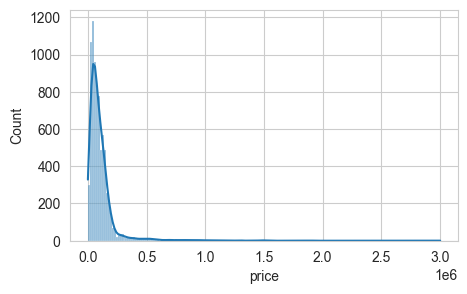

In [36]:
plt.figure(figsize=(5,3))
sns.histplot(df_clean['price'],kde=True)

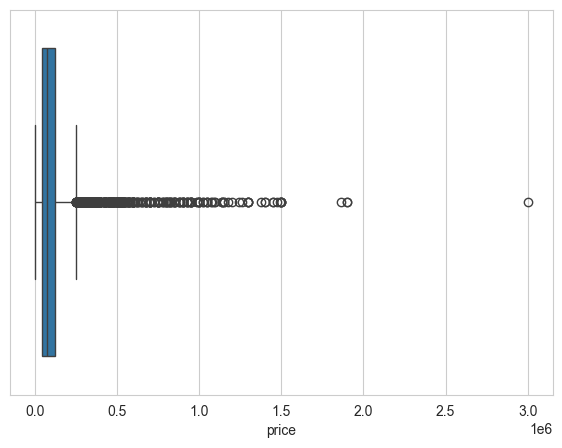

In [37]:
plt.figure(figsize=(7,5))
sns.boxplot(x=df_clean['price'])
plt.xlabel('price')
plt.show()

In [38]:
df_clean['brand']=df_clean['model_name'].str.split().str[0]

In [39]:
df_clean['brand'].str.lower().unique()

array(['bajaj', 'royal', 'hyosung', 'jawa', 'ktm', 'tvs', 'yamaha',
       'honda', 'um', 'hero', 'suzuki', 'husqvarna', 'mahindra',
       'harley-davidson', 'kawasaki', 'benelli', 'triumph', 'ducati',
       'bmw', 'ideal', 'benelliimperiale', 'moto', 'fb', 'indian',
       'yazdi', 'aprilia', 'mv'], dtype=object)

In [40]:
df_clean['brand']=df_clean['model_name'].str.split().str[0].str.lower()

In [41]:
brand_stats=df_clean.groupby('brand')['price'].agg(['median','mean','count']).reset_index()

In [42]:
brand_stats[brand_stats['count']>10]

,brand,median,mean,count
1,bajaj,50000.000000,56963.173872,2105
2,benelli,260000.000000,301581.886792,53
5,ducati,907293.500000,976293.687500,16
7,harley-davidson,450000.000000,512722.602339,171
8,hero,33000.000000,38198.983911,808
9,honda,49749.500000,70906.216981,530
10,husqvarna,205000.000000,206767.000000,11
11,hyosung,193600.000000,213450.555556,54
14,jawa,165000.000000,171286.130435,46
15,kawasaki,465000.000000,496517.701493,67


In [43]:
brand_top_10=brand_stats[brand_stats['count']>3].sort_values(by='median',ascending=False)

<Axes: xlabel='brand', ylabel='median'>

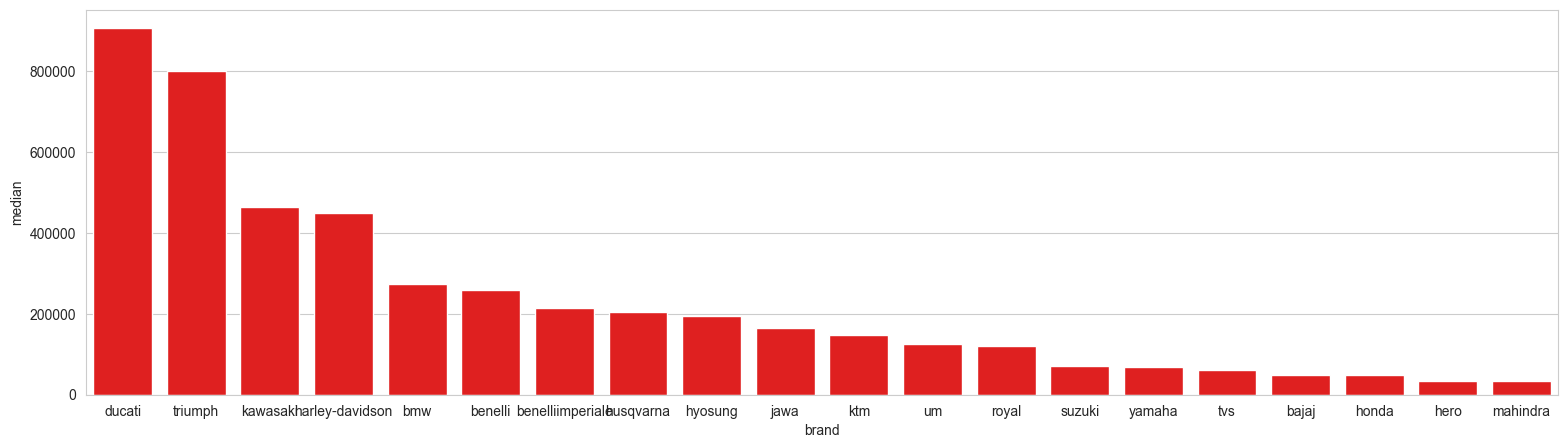

In [44]:
plt.figure(figsize=(19,5))
sns.barplot(data=brand_top_10,x='brand',y='median',color='red',)

In [45]:
df_clean

,model_name,model_year,kms_driven,owner,location,mileage,power,price,bike_age,brand
0,Bajaj Avenger Cruise 220 2017,True,17000.000000,first owner,hyderabad,35.000000,19.000000,63500,True,bajaj
1,Royal Enfield Classic 350cc 2016,True,50000.000000,first owner,hyderabad,35.000000,1980.000000,115000,True,royal
2,Hyosung GT250R 2012,True,14795.000000,first owner,hyderabad,30.000000,28.000000,300000,True,hyosung
3,Bajaj Dominar 400 ABS 2017,True,28.000000,first owner,pondicherry,28.000000,3450.000000,100000,True,bajaj
4,Jawa Perak 330cc 2020,True,2000.000000,first owner,bangalore,NaN,30.000000,197500,True,jawa
...,...,...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,True,7000.000000,first owner,agra,42.000000,16.000000,55000,True,yamaha
7853,Bajaj Discover 100cc 2015,True,80.000000,first owner,delhi,80.000000,77.000000,28000,True,bajaj
7854,Bajaj Pulsar 180cc 2016,True,6407.000000,first owner,bangalore,65.000000,17.000000,61740,True,bajaj
7855,Bajaj V15 150cc 2016,True,7524.000000,first owner,bangalore,57.000000,1180.000000,49000,True,bajaj


In [46]:
df_clean[['kms_driven','price']].corr()

,kms_driven,price
kms_driven,1.000000,-0.114038
price,-0.114038,1.000000


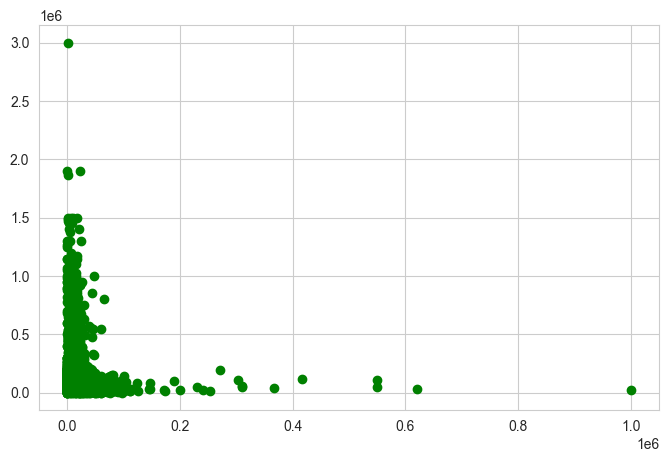

In [47]:
plt.figure(figsize=(8,5))
plt.scatter(data=df_clean,x='kms_driven',y='price',color='green')

In [48]:
plot_data=df_clean.dropna(subset=['kms_driven','price'])
if len(plot_data)>3000:
    plot_data=plot_data.sample(3000,random_state=42)

<Axes: xlabel='kms_driven', ylabel='price'>

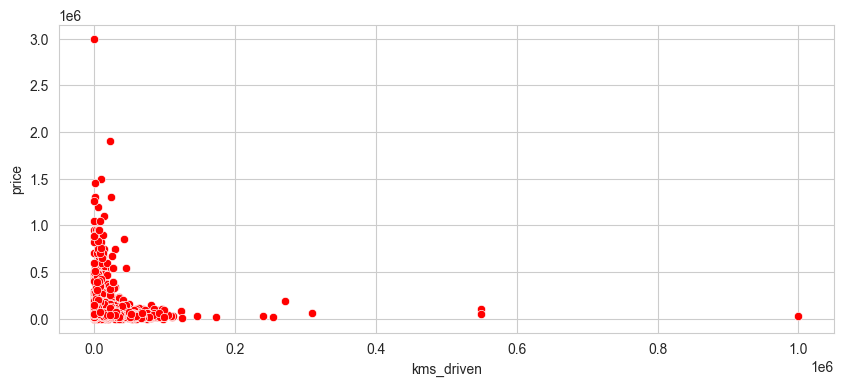

In [49]:
plt.figure(figsize=(10,4))
sns.scatterplot(data=plot_data,x='kms_driven',y='price',color='red')

In [50]:
plot_data=df_clean.dropna(subset=['bike_age','price'])
if len(plot_data)>3000:
    plot_data=plot_data.sample(3000,random_state=42)

<Axes: xlabel='bike_age', ylabel='price'>

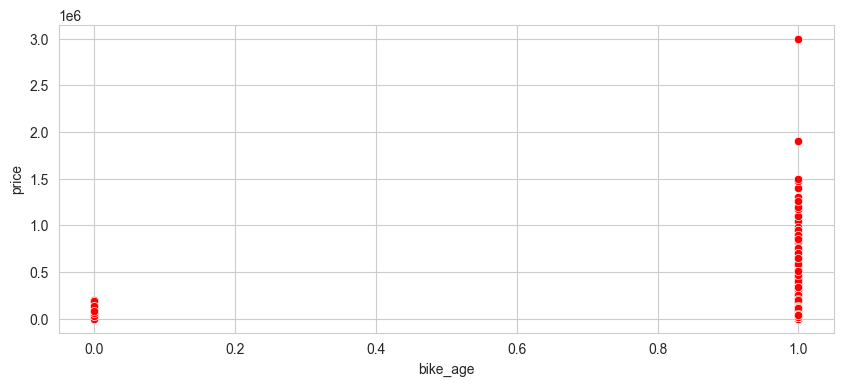

In [51]:
plt.figure(figsize=(10,4))
sns.scatterplot(data=plot_data,x='bike_age',y='price',color='red')

<Axes: >

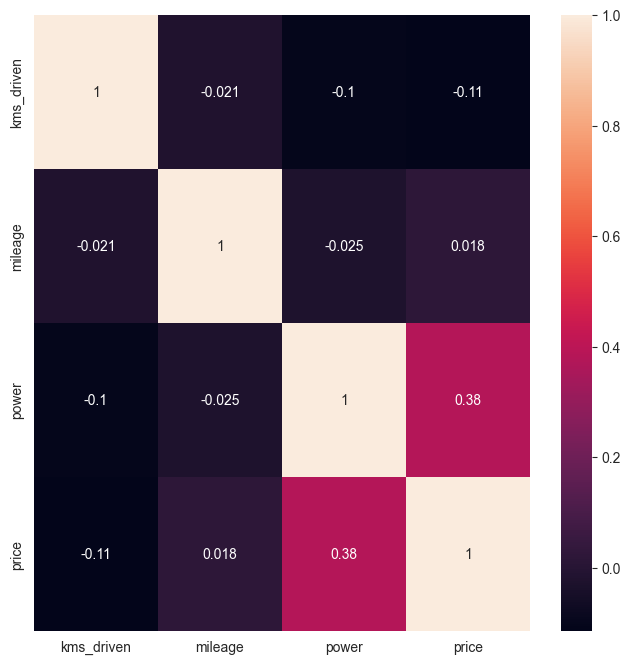

In [52]:
numeric_df=df_clean.select_dtypes(include='number')
plt.figure(figsize=(8,8))
sns.heatmap(numeric_df.corr(),annot=True)

In [53]:
df_clean.dropna(inplace=True)

In [54]:
df_clean.reset_index(inplace=True,drop='first')

In [55]:
data=df_clean.drop(['model_name','location'],axis=1)

In [56]:
data.columns

Index(['model_year', 'kms_driven', 'owner', 'mileage', 'power', 'price',
       'bike_age', 'brand'],
      dtype='str')

In [57]:
x=data[['model_year', 'kms_driven', 'owner', 'mileage', 'power','bike_age', 'brand']]
y=data['price']

In [58]:
from sklearn.model_selection import train_test_split
x_train,x_trest,y_train,y_test=train_test_split(
    x,y,random_state=42,test_size=0.2
)


In [77]:
numerical_column=x.select_dtypes(include='number').columns.tolist()
categorical_column=x.select_dtypes(exclude='number').columns.tolist()

In [78]:
numerical=Pipeline(steps=[('imputer',SimpleImputer(strategy='median'))])
categorical=Pipeline(steps=[('imputer',SimpleImputer(strategy='most_frequent')),
                        ('ohe',OneHotEncoder(handle_unknown='ignore'))])

In [ ]:
transformers=[]
if numerical_column:
    transformers.append(('numeric',numeric_pipeline,numerical_column))
if categorical_column:
    transformers.append(('categorical',categorical_pipeline,categorical_column))

preprocessor=ColumnTransformer(transformers=transformers)
model=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('regression',LinearRegression())
])

model.fit(x_train,y_train)
print('Linear Regression model trained.')

Linear Regression model trained.
